## Day 11 — Preparing Data for Machine Learning

Today's topics
1. Identifying numerical and categorical features.
2. Encoding categorical variables.
3. Scaling numerical features.
4. Separating features (X) from the target (y).
5. Understanding training and testing datasets.


In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv("df_no_missing.csv")
df["OrderDate"]=pd.to_datetime(df["OrderDate"])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   OrderID           12 non-null     int64         
 1   Product           12 non-null     object        
 2   Category          12 non-null     object        
 3   Quantity          12 non-null     int64         
 4   UnitPrice         12 non-null     int64         
 5   Region            12 non-null     object        
 6   OrderDate         12 non-null     datetime64[ns]
 7   Quantity_imputed  12 non-null     bool          
 8   Revenue           12 non-null     int64         
 9   OrderType         12 non-null     object        
 10  CustomerID        12 non-null     int64         
dtypes: bool(1), datetime64[ns](1), int64(5), object(4)
memory usage: 1.1+ KB


name for name in dir(df) if "dtype" in name.lower()

to search for the functions with the keyword "dtype"

In [3]:
numerical=df.select_dtypes(include="number")
corr_matrix=numerical.corr(method="pearson")
corr_matrix

,OrderID,Quantity,UnitPrice,Revenue,CustomerID
OrderID,1.000000,-0.018395,-0.155228,-0.019943,0.663186
Quantity,-0.018395,1.000000,-0.527069,-0.242334,0.051121
UnitPrice,-0.155228,-0.527069,1.000000,0.868642,-0.558770
Revenue,-0.019943,-0.242334,0.868642,1.000000,-0.535774
CustomerID,0.663186,0.051121,-0.558770,-0.535774,1.000000


In [4]:
corr_matrix["Revenue"].sort_values(ascending=False)

Revenue       1.000000
UnitPrice     0.868642
OrderID      -0.019943
Quantity     -0.242334
CustomerID   -0.535774
Name: Revenue, dtype: float64

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

<function matplotlib.pyplot.show(close=None, block=None)>

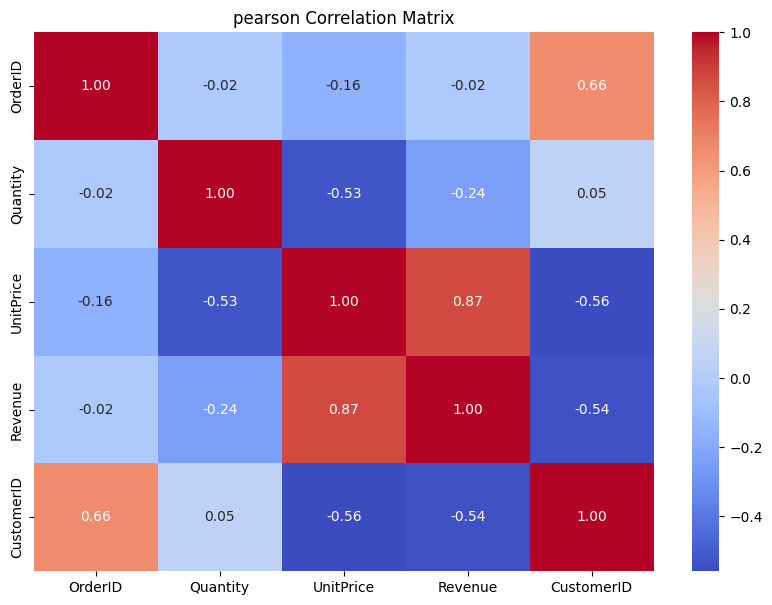

In [6]:
plt.figure(figsize=(10,7))
sns.heatmap(corr_matrix,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("pearson Correlation Matrix")
plt.show

In [12]:
# %pip install statsmodels

In [8]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

In [9]:
X_vif=df[["Quantity","UnitPrice"]]
X_vif.head()

,Quantity,UnitPrice
0,2,800
1,5,20
2,3,50
3,1,800
4,2,250


In [10]:
from statsmodels.tools.tools import add_constant
X_vif=add_constant(X_vif)

In [11]:
vif_data = pd.DataFrame()

vif_data["Feature"] = X_vif.columns

vif_data["VIF"] = [
    variance_inflation_factor(X_vif.values, i)
    for i in range(X_vif.shape[1])
]

vif_data

,Feature,VIF
0,const,1.000000
1,Quantity,1.384661
2,UnitPrice,1.384661


In [13]:
from sklearn.preprocessing import OneHotEncoder

In [14]:
encoder=OneHotEncoder(handle_unknown="ignore",sparse_output=False)

## Two important parameters:
- handle_unknown="ignore": if a new category appears later, the encoder won't raise an error.
- sparse_output=False: return an ordinary array rather than a sparse matrix, which is easier for us to inspect.

In [15]:
categorical_columns=["Product","Category","Region"]
X_categorical=df[categorical_columns]

In [17]:
X_encoded=encoder.fit_transform(X_categorical)

## There are two operations here:
- fit() learns which categories exist in each column.
- transform() converts the categories into binary columns.
  
fit_transform() performs both operations together.

In [20]:
feature_names=encoder.get_feature_names_out(categorical_columns)
df_encoded=pd.DataFrame(X_encoded, columns=feature_names, index=df.index)
df_encoded.head()

,Product_Desk,Product_Keyboard,Product_Laptop,Product_Monitor,Product_Mouse,Category_Electronics,Category_Furniture,Region_East,Region_North,Region_South,Region_West
0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
2,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0


In [22]:
df_encoded.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Product_Desk          12 non-null     float64
 1   Product_Keyboard      12 non-null     float64
 2   Product_Laptop        12 non-null     float64
 3   Product_Monitor       12 non-null     float64
 4   Product_Mouse         12 non-null     float64
 5   Category_Electronics  12 non-null     float64
 6   Category_Furniture    12 non-null     float64
 7   Region_East           12 non-null     float64
 8   Region_North          12 non-null     float64
 9   Region_South          12 non-null     float64
 10  Region_West           12 non-null     float64
dtypes: float64(11)
memory usage: 1.2 KB


In [23]:
feature_names

array(['Product_Desk', 'Product_Keyboard', 'Product_Laptop',
       'Product_Monitor', 'Product_Mouse', 'Category_Electronics',
       'Category_Furniture', 'Region_East', 'Region_North',
       'Region_South', 'Region_West'], dtype=object)

In [24]:
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False,
    drop="first"
)

This would produce only 8 columns instead of 11.

Because with two categories, one column is sufficient to represent the information: if Electronics = 0, it must be Furniture. This is often useful in linear regression to avoid perfect multicollinearity (the dummy variable trap).

In [28]:
from sklearn.preprocessing import StandardScaler
numerical_columns=["Quantity","UnitPrice"]
X_numerical=df[numerical_columns]
scalar=StandardScaler()
X_scaled=scalar.fit_transform(X_numerical)
df_scaled=pd.DataFrame(X_scaled, columns=numerical_columns, index=df.index)

In [29]:
df_scaled.describe()

,Quantity,UnitPrice
count,1.200000e+01,1.200000e+01
mean,1.110223e-16,9.540979e-18
std,1.044466e+00,1.044466e+00
min,-1.270001e+00,-9.350127e-01
25%,-5.080005e-01,-8.611959e-01
50%,-5.080005e-01,-1.804411e-01
75%,4.445004e-01,3.936896e-01
max,1.778002e+00,1.623969e+00


In [31]:
df_scaled.std(ddof=0)
df_scaled.std(ddof=1)

Quantity     1.044466
UnitPrice    1.044466
dtype: float64

### Min-Max Scaling

The transformation formula is:

$$
X_{\text{scaled}} =
\frac{X-X_{\min}}{X_{\max}-X_{\min}}
$$

Where:

- $X$: original value
- $X_{\min}$: minimum value of the feature
- $X_{\max}$: maximum value of the feature
- $X_{\text{scaled}}$: transformed value, between 0 and 1.

For a general target range $[a,b]$:

$$
X_{\text{scaled}} =
a+\frac{(X-X_{\min})(b-a)}
{X_{\max}-X_{\min}}
$$
MinMaxScaler is particularly sensitive to outliers: an extreme value can compress most observations into a small interval.

In [34]:
from sklearn.preprocessing import MinMaxScaler
scaler_mm=MinMaxScaler()
X_minmax=scaler_mm.fit_transform(X_numerical)
df_minmax=pd.DataFrame(X_minmax, columns=numerical_columns, index=df.index)
df_minmax.describe()

,Quantity,UnitPrice
count,12.000000,12.000000
mean,0.416667,0.365385
std,0.342672,0.408157
min,0.000000,0.000000
25%,0.250000,0.028846
50%,0.250000,0.294872
75%,0.562500,0.519231
max,1.000000,1.000000


In [35]:
df_minmax.describe()

,Quantity,UnitPrice
count,12.000000,12.000000
mean,0.416667,0.365385
std,0.342672,0.408157
min,0.000000,0.000000
25%,0.250000,0.028846
50%,0.250000,0.294872
75%,0.562500,0.519231
max,1.000000,1.000000


In [36]:
print(df.columns)

Index(['OrderID', 'Product', 'Category', 'Quantity', 'UnitPrice', 'Region',
       'OrderDate', 'Quantity_imputed', 'Revenue', 'OrderType', 'CustomerID'],
      dtype='object')


In [38]:
y=df["Revenue"]
X=df[["Product","Category","Region"]]
print("Features shape:",X.shape)
print("Target shape:",y.shape)
display(X.head())
display(y.head())


Features shape: (12, 3)
Target shape: (12,)


,Product,Category,Region
0,Laptop,Electronics,North
1,Mouse,Electronics,South
2,Keyboard,Electronics,North
3,Laptop,Electronics,East
4,Monitor,Electronics,West


0    1600
1     100
2     150
3     800
4     500
Name: Revenue, dtype: int64

In [39]:
from sklearn.model_selection import train_test_split
X_train,X_test, y_train,y_test=train_test_split(X,y, test_size=0.2, random_state=42)

In [40]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (9, 3)
X_test: (3, 3)
y_train: (9,)
y_test: (3,)
